# 12B — Kalimantan Spatial-Domain Correction

**Purpose:** correct the spatial domain before wind analysis and graph/GAT modeling.

Notebook 12 showed that the original 17 × 16 rectangular grid contains many cells that are mostly water or outside Indonesian Kalimantan. Therefore, this notebook goes back to the **raw point-level FIRMS detections** and rebuilds the spatial fire panel using an explicit Indonesian Kalimantan land mask.

---

## Why this notebook is necessary

The original pipeline:

```text
rectangular AQ grid
        ↓
all FIRMS points inside the broad Kalimantan bounding box
        ↓
nearest grid-center assignment
        ↓
272-cell panel
```

can retain cells over sea / neighboring islands because the rectangular grid does not follow the shape of Kalimantan.

The corrected logic is:

```text
raw FIRMS point detections
        ↓
keep only points located on Indonesian Kalimantan territory
        ↓
keep only grid cells with meaningful overlap with Indonesian Kalimantan
        ↓
assign retained fire points to the nearest valid grid center
        ↓
rebuild complete cell × date panel
```

---

## Important design principle

This notebook **does not overwrite** the original Notebook 03/04/05 data.

All corrected outputs are saved separately so that:

- the old benchmark remains reproducible;
- the effect of the spatial-domain correction can be quantified;
- downstream weather/features can later be rebuilt on the corrected domain.

---

## Geographic definition

For this thesis, **Kalimantan** means the **Indonesian territory on the island of Borneo**.

The mask is constructed from Natural Earth 10m geographic data by:

1. identifying the Borneo land polygon;
2. intersecting it with Indonesia's administrative-0 polygon.

This excludes the Malaysian and Bruneian parts of Borneo, as well as surrounding non-Kalimantan islands.

In [3]:
# 1. Check/install dependencies

import sys
import subprocess
import importlib.util

required_packages = {
    "geopandas": "geopandas",
    "shapely": "shapely",
    "pyproj": "pyproj",
    "cartopy": "cartopy",
    "scipy": "scipy",
}

missing = [
    pip_name
    for module_name, pip_name in required_packages.items()
    if importlib.util.find_spec(module_name) is None
]

if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *missing]
    )
    print("Installation finished. Restart the kernel once if an import still fails.")
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [4]:
# 2. Imports and reproducibility

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

from shapely.geometry import Point, box
from shapely.ops import unary_union

from scipy.spatial import cKDTree

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io import shapereader

warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

print("GeoPandas:", gpd.__version__)

GeoPandas: 1.1.4


## 3. Resolve project paths

This follows the same project structure used in Notebook 03:

- raw FIRMS: `data/raw/kalimantan/fire_firms/hourly`
- AQ grid: `data/raw/kalimantan/air_quality_openmeteo/hourly`
- original fire panel: `data/intermediate/fire_kalimantan_cell_day_full.csv`

In [5]:
# 3. Project paths

cwd = Path.cwd()

candidate_roots = [
    cwd,
    cwd.parent,
    Path("/content/skripsi-karhut"),
    Path("/content/drive/MyDrive/skripsi-karhut"),
]

PROJECT_ROOT = None

for candidate in candidate_roots:
    fire_dir_candidate = (
        candidate
        / "data"
        / "raw"
        / "kalimantan"
        / "fire_firms"
        / "hourly"
    )

    aq_dir_candidate = (
        candidate
        / "data"
        / "raw"
        / "kalimantan"
        / "air_quality_openmeteo"
        / "hourly"
    )

    if fire_dir_candidate.exists() and aq_dir_candidate.exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Project root could not be detected automatically.\n"
        "Set PROJECT_ROOT manually to the folder containing data/raw/kalimantan."
    )

FIRE_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "kalimantan"
    / "fire_firms"
    / "hourly"
)

AQ_DIR = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "kalimantan"
    / "air_quality_openmeteo"
    / "hourly"
)

ORIGINAL_PANEL_PATH = (
    PROJECT_ROOT
    / "data"
    / "intermediate"
    / "fire_kalimantan_cell_day_full.csv"
)

NB12_SUMMARY_PATH = (
    PROJECT_ROOT
    / "model_results"
    / "spatial_zoom_landwater"
    / "kalimantan_cell_spatial_summary.csv"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "data"
    / "intermediate"
    / "spatial_corrected"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "model_results"
    / "spatial_domain_correction"
)

FIGURES_DIR = RESULTS_DIR / "figures"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT       :", PROJECT_ROOT)
print("FIRMS directory    :", FIRE_DIR)
print("AQ directory       :", AQ_DIR)
print("Original panel     :", ORIGINAL_PANEL_PATH)
print("Corrected output   :", OUTPUT_DIR)
print("Analysis results   :", RESULTS_DIR)

PROJECT_ROOT       : c:\Users\Asus\Documents\skripsi-karhut
FIRMS directory    : c:\Users\Asus\Documents\skripsi-karhut\data\raw\kalimantan\fire_firms\hourly
AQ directory       : c:\Users\Asus\Documents\skripsi-karhut\data\raw\kalimantan\air_quality_openmeteo\hourly
Original panel     : c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\fire_kalimantan_cell_day_full.csv
Corrected output   : c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\spatial_corrected
Analysis results   : c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_domain_correction


## 4. Load the raw FIRMS detections

All daily FIRMS CSVs are loaded again so the correction is performed **before** spatial aggregation.

The notebook expects the same core fields used by Notebook 03:

- `time_utc`
- `lat`
- `lon`
- `frp`

Empty daily files are allowed.

In [6]:
# 4. Load all raw FIRMS files

fire_files = sorted(FIRE_DIR.glob("*.csv"))

if not fire_files:
    raise FileNotFoundError(f"No FIRMS CSV files found in {FIRE_DIR}")

print("FIRMS files:", len(fire_files))
print("First:", fire_files[0].name)
print("Last :", fire_files[-1].name)

frames = []
empty_files = 0

for path in fire_files:
    try:
        temp = pd.read_csv(path)
    except pd.errors.EmptyDataError:
        empty_files += 1
        continue

    if temp.empty:
        empty_files += 1
        continue

    temp["source_file"] = path.name
    frames.append(temp)

if not frames:
    raise ValueError("All FIRMS files are empty.")

fire_raw = pd.concat(frames, ignore_index=True)

required_cols = {"time_utc", "lat", "lon", "frp"}
missing_cols = sorted(required_cols - set(fire_raw.columns))

if missing_cols:
    raise ValueError(f"Missing FIRMS columns: {missing_cols}")

fire_raw["time_utc"] = pd.to_datetime(
    fire_raw["time_utc"],
    errors="coerce",
    utc=False,
)

for col in ["lat", "lon", "frp"]:
    fire_raw[col] = pd.to_numeric(
        fire_raw[col],
        errors="coerce",
    )

bad_required = fire_raw[
    ["time_utc", "lat", "lon", "frp"]
].isna().any(axis=1).sum()

if bad_required:
    print(
        "WARNING:",
        bad_required,
        "rows have missing/unparseable required values and will be removed.",
    )

fire_raw = fire_raw.dropna(
    subset=["time_utc", "lat", "lon", "frp"]
).reset_index(drop=True)

print()
print("Empty daily files       :", empty_files)
print("Raw point detections    :", len(fire_raw))
print(
    "Raw date range          :",
    fire_raw["time_utc"].min(),
    "→",
    fire_raw["time_utc"].max(),
)
print(
    "Raw coordinate bounds   :",
    "lat",
    (fire_raw["lat"].min(), fire_raw["lat"].max()),
    "| lon",
    (fire_raw["lon"].min(), fire_raw["lon"].max()),
)

FIRMS files: 134
First: fires_2026-05-01.csv
Last : fires_2026-09-11.csv

Empty daily files       : 8
Raw point detections    : 146314
Raw date range          : 2026-05-01 06:00:00 → 2026-09-11 06:00:00
Raw coordinate bounds   : lat (np.float64(-4.26212), np.float64(7.38579)) | lon (np.float64(108.00037), np.float64(119.49989))


## 5. Load the original AQ grid

The corrected pipeline keeps the same 0.75° analysis-grid geometry so that the spatial correction can be isolated from a grid-resolution change.

The AQ values themselves are not used here.

In [7]:
# 5. Obtain the static AQ spatial grid

aq_files = sorted(AQ_DIR.glob("*.csv"))

if not aq_files:
    raise FileNotFoundError(f"No AQ CSV files found in {AQ_DIR}")

aq_sample = pd.read_csv(aq_files[0])

required_aq = {"lat", "lon"}
missing_aq = sorted(required_aq - set(aq_sample.columns))

if missing_aq:
    raise ValueError(f"Missing AQ grid columns: {missing_aq}")

grid = (
    aq_sample[["lat", "lon"]]
    .drop_duplicates()
    .sort_values(["lat", "lon"])
    .reset_index(drop=True)
    .rename(
        columns={
            "lat": "grid_lat",
            "lon": "grid_lon",
        }
    )
)

grid_lats = np.sort(grid["grid_lat"].unique())
grid_lons = np.sort(grid["grid_lon"].unique())

lat_step = float(np.median(np.diff(grid_lats)))
lon_step = float(np.median(np.diff(grid_lons)))

print("AQ sample :", aq_files[0].name)
print("Grid cells:", len(grid))
print("Latitudes :", len(grid_lats))
print("Longitudes:", len(grid_lons))
print("Lat step  :", lat_step)
print("Lon step  :", lon_step)

if len(grid) != 272:
    print(
        "WARNING: expected 272 cells from the original pipeline,",
        "but found",
        len(grid),
    )

AQ sample : pm25_2026-09-07.csv
Grid cells: 272
Latitudes : 17
Longitudes: 16
Lat step  : 0.75
Lon step  : 0.75


## 6. Build the original 0.75° cell polygons

Each AQ coordinate is treated as the cell center.

The cell polygon extends half a grid step in each direction.

In [8]:
# 6. Original rectangular cell polygons

half_lat = lat_step / 2
half_lon = lon_step / 2

grid["region"] = "Kalimantan"

grid["cell_id"] = (
    grid["region"]
    + "_"
    + grid["grid_lat"].map(lambda x: f"{x:.2f}")
    + "_"
    + grid["grid_lon"].map(lambda x: f"{x:.2f}")
)

grid["geometry"] = [
    box(
        lon - half_lon,
        lat - half_lat,
        lon + half_lon,
        lat + half_lat,
    )
    for lat, lon in zip(
        grid["grid_lat"],
        grid["grid_lon"],
    )
]

grid_gdf = gpd.GeoDataFrame(
    grid,
    geometry="geometry",
    crs="EPSG:4326",
)

display(grid_gdf.head())

,grid_lat,grid_lon,region,cell_id,geometry
0,-4.5,108.00,Kalimantan,Kalimantan_-4.50_108.00,"POLYGON ((108.375 -4.875, 108.375 -4.125, 107...."
1,-4.5,108.75,Kalimantan,Kalimantan_-4.50_108.75,"POLYGON ((109.125 -4.875, 109.125 -4.125, 108...."
2,-4.5,109.50,Kalimantan,Kalimantan_-4.50_109.50,"POLYGON ((109.875 -4.875, 109.875 -4.125, 109...."
3,-4.5,110.25,Kalimantan,Kalimantan_-4.50_110.25,"POLYGON ((110.625 -4.875, 110.625 -4.125, 109...."
4,-4.5,111.00,Kalimantan,Kalimantan_-4.50_111.00,"POLYGON ((111.375 -4.875, 111.375 -4.125, 110...."


## 7. Load Natural Earth land and country polygons

The first spatial operation identifies the **Borneo island land polygon**.

Then that island polygon is intersected with the **Indonesia** country polygon to obtain Indonesian Kalimantan.

In [9]:
# 7. Natural Earth sources

NE_RESOLUTION = "10m"

land_path = shapereader.natural_earth(
    resolution=NE_RESOLUTION,
    category="physical",
    name="land",
)

countries_path = shapereader.natural_earth(
    resolution=NE_RESOLUTION,
    category="cultural",
    name="admin_0_countries",
)

print("Natural Earth land:", land_path)
print("Natural Earth countries:", countries_path)

c:\Users\Asus\Documents\skripsi-karhut\.venv\Lib\site-packages\cartopy\io\__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_cultural/ne_10m_admin_0_countries.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


Natural Earth land: C:\Users\Asus\.local\share\cartopy\shapefiles\natural_earth\physical\ne_10m_land.shp
Natural Earth countries: C:\Users\Asus\.local\share\cartopy\shapefiles\natural_earth\cultural\ne_10m_admin_0_countries.shp


## 8. Identify the Borneo island polygon

A seed point well inside Borneo is used only to identify the correct connected land polygon from Natural Earth.

The seed is **not** used as a study-area boundary.

In [10]:
# 8. Identify Borneo as a connected Natural Earth land polygon

BORNEO_SEED = Point(114.0, 0.5)

land_reader = shapereader.Reader(land_path)
borneo_candidates = []

for geom in land_reader.geometries():
    if geom.contains(BORNEO_SEED) or geom.covers(BORNEO_SEED):
        borneo_candidates.append(geom)

if not borneo_candidates:
    raise RuntimeError(
        "Could not identify the Borneo land polygon from Natural Earth."
    )

borneo_geom = unary_union(borneo_candidates)

print("Borneo geometry type:", borneo_geom.geom_type)
print("Borneo bounds:", borneo_geom.bounds)

borneo_gdf = gpd.GeoDataFrame(
    {"name": ["Borneo"]},
    geometry=[borneo_geom],
    crs="EPSG:4326",
)

Borneo geometry type: MultiPolygon
Borneo bounds: (-179.99999999999991, -89.99999999999994, 180.0, 83.63410065300008)


## 9. Extract Indonesia's territory on Borneo

Natural Earth country geometry is used to separate Indonesian Kalimantan from:

- Malaysian Borneo
- Brunei

The intersection of `Indonesia ∩ Borneo` becomes the spatial domain mask.

In [11]:
# 9. Indonesia ∩ Borneo = Indonesian Kalimantan

country_records = list(
    shapereader.Reader(countries_path).records()
)

indonesia_geoms = []

for rec in country_records:
    attrs = rec.attributes

    name_candidates = {
        str(attrs.get("ADMIN", "")),
        str(attrs.get("NAME", "")),
        str(attrs.get("NAME_EN", "")),
        str(attrs.get("SOVEREIGNT", "")),
        str(attrs.get("ADM0_A3", "")),
    }

    if (
        "Indonesia" in name_candidates
        or "IDN" in name_candidates
    ):
        indonesia_geoms.append(rec.geometry)

if not indonesia_geoms:
    raise RuntimeError(
        "Indonesia country polygon was not found in Natural Earth."
    )

indonesia_geom = unary_union(indonesia_geoms)
kalimantan_geom = indonesia_geom.intersection(borneo_geom)

if kalimantan_geom.is_empty:
    raise RuntimeError("Indonesia ∩ Borneo produced an empty geometry.")

print("Kalimantan geometry type:", kalimantan_geom.geom_type)
print("Kalimantan bounds:", kalimantan_geom.bounds)

kalimantan_gdf = gpd.GeoDataFrame(
    {"name": ["Indonesian Kalimantan"]},
    geometry=[kalimantan_geom],
    crs="EPSG:4326",
)

Kalimantan geometry type: MultiPolygon
Kalimantan bounds: (95.19727623800003, -9.106133721999925, 140.97762699400005, 5.654689846000053)


## 10. Visual sanity check of the corrected geographic domain

The full rectangular grid is shown together with the Indonesian Kalimantan polygon.

This figure should make the original domain problem visually obvious.

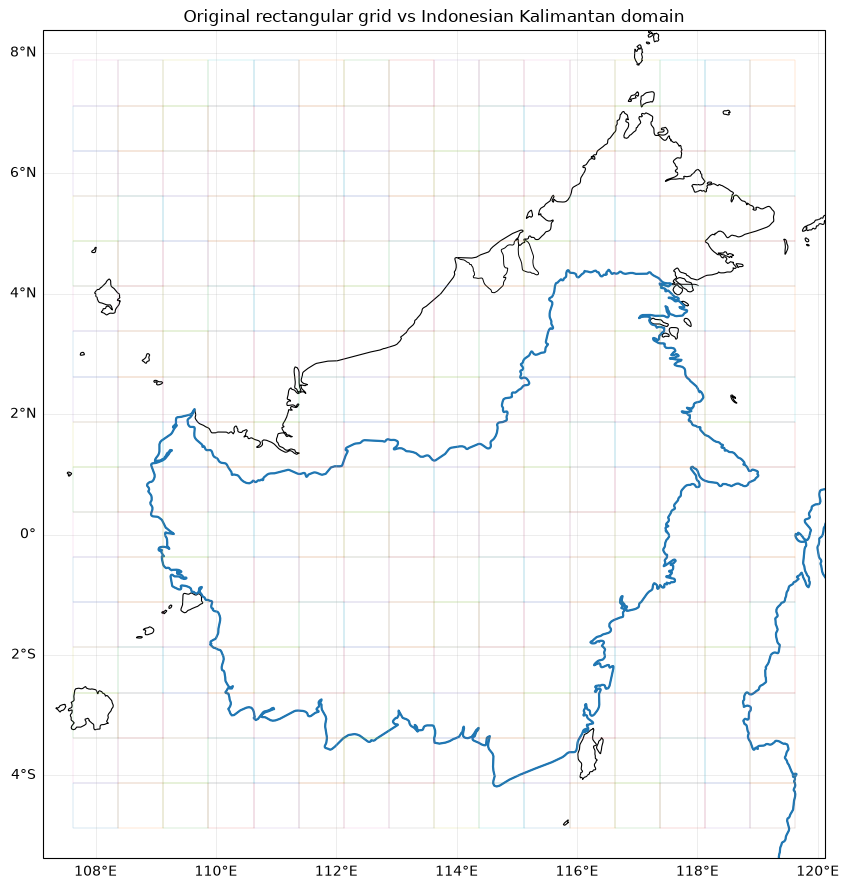

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_domain_correction\figures\01_original_grid_vs_kalimantan_domain.png


In [12]:
# 10. Geographic-domain sanity map

minx, miny, maxx, maxy = grid_gdf.total_bounds

fig = plt.figure(figsize=(10, 9))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(
    [minx - 0.5, maxx + 0.5, miny - 0.5, maxy + 0.5],
    crs=ccrs.PlateCarree(),
)

ax.add_feature(
    cfeature.COASTLINE.with_scale("10m"),
    linewidth=0.8,
)

ax.add_feature(
    cfeature.BORDERS.with_scale("10m"),
    linewidth=0.7,
)

kalimantan_gdf.boundary.plot(
    ax=ax,
    linewidth=1.6,
    transform=ccrs.PlateCarree(),
)

for geom in grid_gdf.geometry:
    x, y = geom.exterior.xy
    ax.plot(
        x,
        y,
        linewidth=0.35,
        alpha=0.35,
        transform=ccrs.PlateCarree(),
    )

ax.set_title(
    "Original rectangular grid vs Indonesian Kalimantan domain"
)

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    alpha=0.4,
)
gl.top_labels = False
gl.right_labels = False

plt.tight_layout()

fig_path = FIGURES_DIR / "01_original_grid_vs_kalimantan_domain.png"
plt.savefig(fig_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 11. Compute each cell's overlap with Indonesian Kalimantan

Area calculations use **EPSG:6933**, a global equal-area CRS.

For each rectangular cell:

\[
kalimantan\_overlap\_fraction =

rac{	ext{cell area inside Indonesian Kalimantan}}
{	ext{total rectangular cell area}}
\]

We also record whether the **cell center** lies inside Indonesian Kalimantan.

In [13]:
# 11. Cell overlap with Indonesian Kalimantan

AREA_CRS = "EPSG:6933"

grid_equal = grid_gdf.to_crs(AREA_CRS)
kalimantan_equal = (
    kalimantan_gdf.to_crs(AREA_CRS)
    .geometry
    .iloc[0]
)

grid_equal["cell_area_km2"] = (
    grid_equal.geometry.area / 1_000_000
)

grid_equal["kalimantan_area_km2"] = (
    grid_equal.geometry
    .intersection(kalimantan_equal)
    .area
    / 1_000_000
)

grid_equal["kalimantan_overlap_fraction"] = (
    grid_equal["kalimantan_area_km2"]
    / grid_equal["cell_area_km2"]
).clip(0, 1)

grid_gdf["cell_area_km2"] = (
    grid_equal["cell_area_km2"].to_numpy()
)

grid_gdf["kalimantan_area_km2"] = (
    grid_equal["kalimantan_area_km2"].to_numpy()
)

grid_gdf["kalimantan_overlap_fraction"] = (
    grid_equal["kalimantan_overlap_fraction"].to_numpy()
)

grid_gdf["center_inside_kalimantan"] = [
    kalimantan_geom.covers(
        Point(lon, lat)
    )
    for lat, lon in zip(
        grid_gdf["grid_lat"],
        grid_gdf["grid_lon"],
    )
]

display(
    grid_gdf[
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
            "kalimantan_overlap_fraction",
            "center_inside_kalimantan",
        ]
    ]
    .sort_values("kalimantan_overlap_fraction")
    .head(25)
)

,cell_id,grid_lat,grid_lon,kalimantan_overlap_fraction,center_inside_kalimantan
16,Kalimantan_-3.75_108.00,-3.75,108.00,0.0,False
17,Kalimantan_-3.75_108.75,-3.75,108.75,0.0,False
18,Kalimantan_-3.75_109.50,-3.75,109.50,0.0,False
19,Kalimantan_-3.75_110.25,-3.75,110.25,0.0,False
20,Kalimantan_-3.75_111.00,-3.75,111.00,0.0,False
240,Kalimantan_6.75_108.00,6.75,108.00,0.0,False
28,Kalimantan_-3.75_117.00,-3.75,117.00,0.0,False
29,Kalimantan_-3.75_117.75,-3.75,117.75,0.0,False
241,Kalimantan_6.75_108.75,6.75,108.75,0.0,False
248,Kalimantan_6.75_114.00,6.75,114.00,0.0,False


## 12. Threshold-sensitivity analysis for valid graph nodes

A hard overlap threshold is necessarily a modeling choice because the analysis grid is coarse.

This notebook reports several alternatives:

- 5%
- 10%
- 20%
- 30%
- 50%

The default working threshold is **20% overlap**.

A cell is kept if either:

1. at least 20% of its rectangular area overlaps Indonesian Kalimantan, **or**
2. its center lies inside Indonesian Kalimantan.

The center rule prevents a narrow coastal geometry from accidentally excluding an otherwise meaningful cell.

The threshold remains explicit so it can be changed after review.

In [14]:
# 12. Node-mask sensitivity

OVERLAP_THRESHOLDS = [0.05, 0.10, 0.20, 0.30, 0.50]
DEFAULT_OVERLAP_THRESHOLD = 0.20

threshold_rows = []

for threshold in OVERLAP_THRESHOLDS:
    keep = (
        (grid_gdf["kalimantan_overlap_fraction"] >= threshold)
        |
        grid_gdf["center_inside_kalimantan"]
    )

    threshold_rows.append({
        "overlap_threshold": threshold,
        "kept_cells": int(keep.sum()),
        "excluded_cells": int((~keep).sum()),
    })

threshold_summary = pd.DataFrame(threshold_rows)
display(threshold_summary)

grid_gdf["keep_corrected"] = (
    (
        grid_gdf["kalimantan_overlap_fraction"]
        >= DEFAULT_OVERLAP_THRESHOLD
    )
    |
    grid_gdf["center_inside_kalimantan"]
)

valid_grid = (
    grid_gdf[
        grid_gdf["keep_corrected"]
    ]
    .copy()
    .reset_index(drop=True)
)

invalid_grid = (
    grid_gdf[
        ~grid_gdf["keep_corrected"]
    ]
    .copy()
    .reset_index(drop=True)
)

print("Original cells :", len(grid_gdf))
print("Valid cells    :", len(valid_grid))
print("Excluded cells :", len(invalid_grid))

,overlap_threshold,kept_cells,excluded_cells
0,0.05,106,166
1,0.10,97,175
2,0.20,94,178
3,0.30,86,186
4,0.50,80,192


Original cells : 272
Valid cells    : 94
Excluded cells : 178


## 13. Compare Notebook 12's old land/water rule with the corrected Kalimantan-overlap rule

Notebook 12 used generic land fraction and found many water-dominant cells.

Here we compare that earlier diagnostic against the more specific question:

> Does this grid cell meaningfully overlap **Indonesian Kalimantan**?

This avoids treating land on nearby islands as valid Kalimantan land.

In [15]:
# 13. Optional comparison with Notebook 12

if NB12_SUMMARY_PATH.exists():
    old_summary = pd.read_csv(NB12_SUMMARY_PATH)

    compare_cols = [
        "cell_id",
        "land_fraction",
        "surface_class",
        "total_fire_count",
        "emerging_7d_all",
    ]

    compare_cols = [
        c
        for c in compare_cols
        if c in old_summary.columns
    ]

    mask_comparison = (
        grid_gdf[
            [
                "cell_id",
                "kalimantan_overlap_fraction",
                "center_inside_kalimantan",
                "keep_corrected",
            ]
        ]
        .merge(
            old_summary[compare_cols],
            on="cell_id",
            how="left",
            validate="one_to_one",
        )
    )

    display(
        mask_comparison[
            [
                c
                for c in [
                    "cell_id",
                    "land_fraction",
                    "kalimantan_overlap_fraction",
                    "center_inside_kalimantan",
                    "keep_corrected",
                    "total_fire_count",
                ]
                if c in mask_comparison.columns
            ]
        ]
        .sort_values(
            "kalimantan_overlap_fraction"
        )
        .head(30)
    )
else:
    mask_comparison = None
    print(
        "Notebook 12 summary not found; continuing without old-mask comparison."
    )

,cell_id,land_fraction,kalimantan_overlap_fraction,center_inside_kalimantan,keep_corrected,total_fire_count
16,Kalimantan_-3.75_108.00,0.000000,0.0,False,False,0.0
17,Kalimantan_-3.75_108.75,0.000000,0.0,False,False,0.0
18,Kalimantan_-3.75_109.50,0.000000,0.0,False,False,0.0
19,Kalimantan_-3.75_110.25,0.000000,0.0,False,False,0.0
20,Kalimantan_-3.75_111.00,0.000000,0.0,False,False,0.0
240,Kalimantan_6.75_108.00,0.000000,0.0,False,False,0.0
28,Kalimantan_-3.75_117.00,0.000000,0.0,False,False,0.0
29,Kalimantan_-3.75_117.75,0.000000,0.0,False,False,0.0
241,Kalimantan_6.75_108.75,0.000000,0.0,False,False,0.0
248,Kalimantan_6.75_114.00,0.000000,0.0,False,False,0.0


## 14. Map the corrected valid/invalid grid cells

This is the main graph-domain figure.

Cells shown as retained should follow the Indonesian Kalimantan landmass much more closely than the original rectangle.

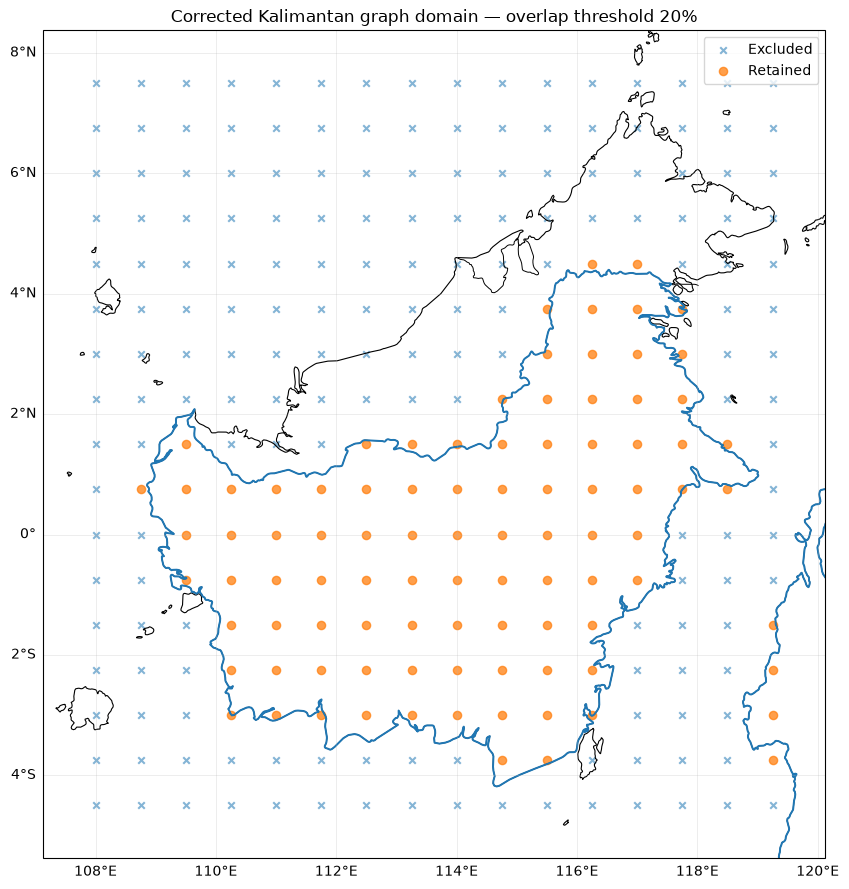

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_domain_correction\figures\02_corrected_valid_grid_cells.png


In [16]:
# 14. Corrected node-domain map

fig = plt.figure(figsize=(10, 9))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(
    [minx - 0.5, maxx + 0.5, miny - 0.5, maxy + 0.5],
    crs=ccrs.PlateCarree(),
)

ax.add_feature(
    cfeature.COASTLINE.with_scale("10m"),
    linewidth=0.8,
)

ax.add_feature(
    cfeature.BORDERS.with_scale("10m"),
    linewidth=0.7,
)

kalimantan_gdf.boundary.plot(
    ax=ax,
    linewidth=1.4,
    transform=ccrs.PlateCarree(),
)

ax.scatter(
    invalid_grid["grid_lon"],
    invalid_grid["grid_lat"],
    s=22,
    marker="x",
    alpha=0.55,
    label="Excluded",
    transform=ccrs.PlateCarree(),
)

ax.scatter(
    valid_grid["grid_lon"],
    valid_grid["grid_lat"],
    s=35,
    alpha=0.75,
    label="Retained",
    transform=ccrs.PlateCarree(),
)

ax.legend()

ax.set_title(
    f"Corrected Kalimantan graph domain — overlap threshold {DEFAULT_OVERLAP_THRESHOLD:.0%}"
)

gl = ax.gridlines(
    draw_labels=True,
    linewidth=0.4,
    alpha=0.4,
)
gl.top_labels = False
gl.right_labels = False

plt.tight_layout()

fig_path = FIGURES_DIR / "02_corrected_valid_grid_cells.png"
plt.savefig(fig_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 15. Spatially filter raw FIRMS points to Indonesian Kalimantan

This is the most important correction.

The raw fire points are converted to point geometries, then retained only if their coordinates fall inside / on the Indonesian Kalimantan polygon.

This means outside-island detections are removed **before** nearest-grid assignment.

In [17]:
# 15. Raw FIRMS point filtering

fire_points = gpd.GeoDataFrame(
    fire_raw.copy(),
    geometry=gpd.points_from_xy(
        fire_raw["lon"],
        fire_raw["lat"],
    ),
    crs="EPSG:4326",
)

inside_mask = fire_points.geometry.apply(
    kalimantan_geom.covers
)

fire_kalimantan = (
    fire_points[
        inside_mask
    ]
    .copy()
    .reset_index(drop=True)
)

fire_removed = (
    fire_points[
        ~inside_mask
    ]
    .copy()
    .reset_index(drop=True)
)

print("Raw FIRMS detections                 :", len(fire_points))
print("Inside Indonesian Kalimantan         :", len(fire_kalimantan))
print("Outside Indonesian Kalimantan removed:", len(fire_removed))

print(
    "Retention rate:",
    round(
        100 * len(fire_kalimantan) / len(fire_points),
        3,
    ),
    "%",
)

Raw FIRMS detections                 : 146314
Inside Indonesian Kalimantan         : 140171
Outside Indonesian Kalimantan removed: 6143
Retention rate: 95.801 %


## 16. Inspect removed FIRMS detections

This diagnostic tells us whether the original "Kalimantan" raw folder contained substantial fire detections outside the intended Indonesian Kalimantan domain.

Only descriptive coordinates are shown.

In [18]:
# 16. Removed-point diagnostics

if len(fire_removed):
    removed_summary = pd.Series({
        "n_removed": len(fire_removed),
        "lat_min": fire_removed["lat"].min(),
        "lat_max": fire_removed["lat"].max(),
        "lon_min": fire_removed["lon"].min(),
        "lon_max": fire_removed["lon"].max(),
        "frp_sum": fire_removed["frp"].sum(),
    })

    display(
        removed_summary.to_frame("value")
    )
else:
    print("No FIRMS points were removed.")

,value
n_removed,6143.00000
lat_min,-4.26212
lat_max,7.38579
lon_min,108.00037
lon_max,119.49854
frp_sum,47204.98000


## 17. Map retained versus removed FIRMS points

For readability, a reproducible sample is plotted if there are many points.

This figure should confirm that retained points lie on Indonesian Kalimantan.

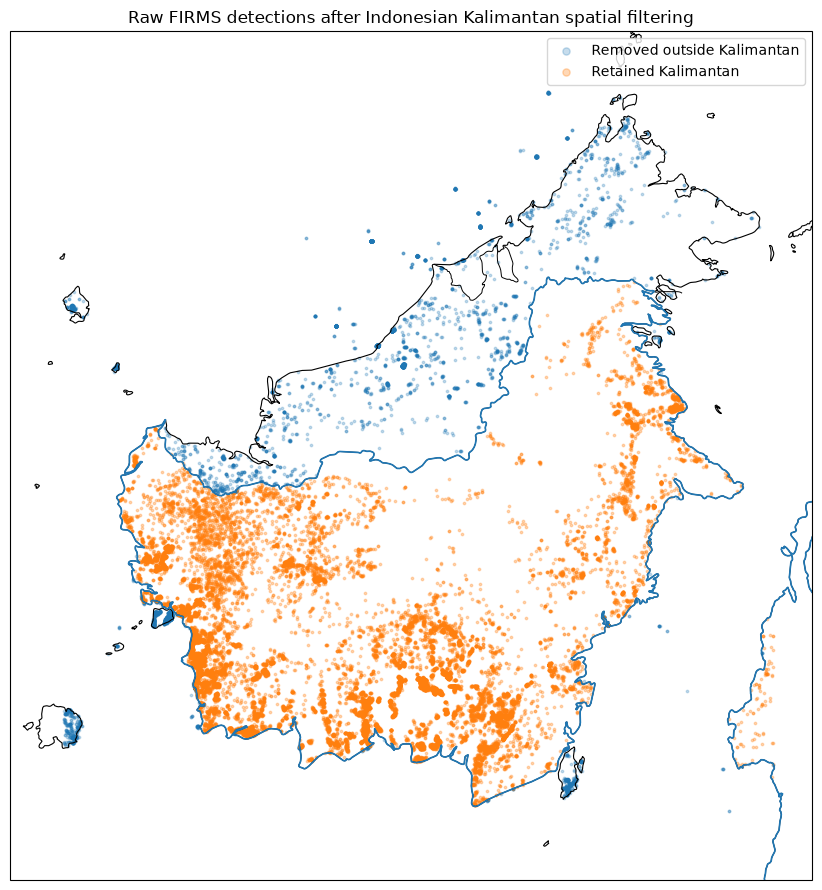

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_domain_correction\figures\03_raw_firms_spatial_filter.png


In [19]:
# 17. Retained vs removed point map

MAX_PLOT_POINTS = 25000

retained_plot = (
    fire_kalimantan.sample(
        n=min(MAX_PLOT_POINTS, len(fire_kalimantan)),
        random_state=RANDOM_STATE,
    )
    if len(fire_kalimantan)
    else fire_kalimantan
)

removed_plot = (
    fire_removed.sample(
        n=min(MAX_PLOT_POINTS, len(fire_removed)),
        random_state=RANDOM_STATE,
    )
    if len(fire_removed)
    else fire_removed
)

fig = plt.figure(figsize=(10, 9))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(
    [minx - 0.5, maxx + 0.5, miny - 0.5, maxy + 0.5],
    crs=ccrs.PlateCarree(),
)

ax.add_feature(
    cfeature.COASTLINE.with_scale("10m"),
    linewidth=0.8,
)

ax.add_feature(
    cfeature.BORDERS.with_scale("10m"),
    linewidth=0.7,
)

kalimantan_gdf.boundary.plot(
    ax=ax,
    linewidth=1.2,
    transform=ccrs.PlateCarree(),
)

if len(removed_plot):
    ax.scatter(
        removed_plot["lon"],
        removed_plot["lat"],
        s=3,
        alpha=0.25,
        label="Removed outside Kalimantan",
        transform=ccrs.PlateCarree(),
    )

if len(retained_plot):
    ax.scatter(
        retained_plot["lon"],
        retained_plot["lat"],
        s=3,
        alpha=0.30,
        label="Retained Kalimantan",
        transform=ccrs.PlateCarree(),
    )

ax.legend(markerscale=3)

ax.set_title(
    "Raw FIRMS detections after Indonesian Kalimantan spatial filtering"
)

plt.tight_layout()

fig_path = FIGURES_DIR / "03_raw_firms_spatial_filter.png"
plt.savefig(fig_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 18. Assign retained FIRMS points to the nearest **valid** grid center

The earlier pipeline assigned fire points to the nearest center among all 272 rectangular cells.

The corrected pipeline restricts candidate centers to `valid_grid`.

Nearest-neighbor search is performed in a metric projected CRS.

In [20]:
# 18. Nearest valid grid-center assignment

DISTANCE_CRS = "EPSG:32649"  # UTM 49N; suitable for most of Kalimantan/Borneo

valid_centers = valid_grid[
    [
        "cell_id",
        "grid_lat",
        "grid_lon",
    ]
].copy()

valid_centers["geometry"] = gpd.points_from_xy(
    valid_centers["grid_lon"],
    valid_centers["grid_lat"],
)

valid_centers_gdf = gpd.GeoDataFrame(
    valid_centers,
    geometry="geometry",
    crs="EPSG:4326",
)

valid_centers_metric = (
    valid_centers_gdf.to_crs(DISTANCE_CRS)
)

fire_metric = (
    fire_kalimantan.to_crs(DISTANCE_CRS)
)

center_xy = np.column_stack([
    valid_centers_metric.geometry.x.to_numpy(),
    valid_centers_metric.geometry.y.to_numpy(),
])

fire_xy = np.column_stack([
    fire_metric.geometry.x.to_numpy(),
    fire_metric.geometry.y.to_numpy(),
])

tree = cKDTree(center_xy)

dist_m, nearest_idx = tree.query(
    fire_xy,
    k=1,
)

fire_assigned = fire_kalimantan.copy()

fire_assigned["assigned_center_index"] = nearest_idx
fire_assigned["assignment_distance_km"] = dist_m / 1000

lookup = (
    valid_centers_gdf
    .reset_index(drop=True)
)

fire_assigned["grid_lat"] = lookup.loc[
    nearest_idx,
    "grid_lat",
].to_numpy()

fire_assigned["grid_lon"] = lookup.loc[
    nearest_idx,
    "grid_lon",
].to_numpy()

fire_assigned["cell_id"] = lookup.loc[
    nearest_idx,
    "cell_id",
].to_numpy()

fire_assigned["region"] = "Kalimantan"

print(
    fire_assigned["assignment_distance_km"]
    .describe(
        percentiles=[0.50, 0.90, 0.95, 0.99]
    )
)

print()
print(
    "Max assignment distance:",
    round(
        fire_assigned["assignment_distance_km"].max(),
        3,
    ),
    "km",
)

count    140171.000000
mean         30.543107
std          12.672751
min           0.072055
50%          31.012371
90%          46.680852
95%          50.945099
99%          56.377775
max          73.214863
Name: assignment_distance_km, dtype: float64

Max assignment distance: 73.215 km


## 19. Flag unusually long point-to-grid assignments

A long assignment distance can indicate that the valid-node mask is too restrictive near the coastline / border.

The notebook does **not automatically delete** such observations.

Instead, assignments above 100 km are reported for review.

In [21]:
# 19. Assignment-distance QA

LONG_ASSIGNMENT_KM = 100.0

long_assignments = fire_assigned[
    fire_assigned["assignment_distance_km"]
    > LONG_ASSIGNMENT_KM
].copy()

print(
    f"Assignments > {LONG_ASSIGNMENT_KM:.0f} km:",
    len(long_assignments),
)

if len(long_assignments):
    display(
        long_assignments[
            [
                "time_utc",
                "lat",
                "lon",
                "grid_lat",
                "grid_lon",
                "cell_id",
                "assignment_distance_km",
                "frp",
            ]
        ]
        .sort_values(
            "assignment_distance_km",
            ascending=False,
        )
        .head(30)
    )

Assignments > 100 km: 0


## 20. Aggregate corrected raw detections into cell-day data

This mirrors the main Notebook 03 aggregation:

- `fire_count`
- `frp_sum`
- `frp_mean`
- `frp_max`
- `fire_active`

In [22]:
# 20. Corrected cell-day aggregation

fire_assigned["date"] = (
    pd.to_datetime(
        fire_assigned["time_utc"]
    )
    .dt.normalize()
)

fire_cell_day_corrected = (
    fire_assigned
    .groupby(
        [
            "region",
            "cell_id",
            "grid_lat",
            "grid_lon",
            "date",
        ],
        as_index=False,
    )
    .agg(
        fire_count=("frp", "size"),
        frp_sum=("frp", "sum"),
        frp_mean=("frp", "mean"),
        frp_max=("frp", "max"),
    )
)

fire_cell_day_corrected["fire_active"] = (
    fire_cell_day_corrected["fire_count"]
    > 0
).astype(int)

print("Observed corrected cell-days:", len(fire_cell_day_corrected))
print(
    "Corrected cells with >=1 fire:",
    fire_cell_day_corrected["cell_id"].nunique(),
)
print(
    "Corrected detection total:",
    int(fire_cell_day_corrected["fire_count"].sum()),
)

Observed corrected cell-days: 4792
Corrected cells with >=1 fire: 91
Corrected detection total: 140171


## 21. Build the corrected complete cell × date panel

All **valid corrected cells** are crossed with every study date.

Missing fire observations become explicit zeros.

This preserves the same interpretation:

- `fire_active = 1`: at least one FIRMS detection observed in that corrected cell-day;
- `fire_active = 0`: no FIRMS detection observed, **not proof of no fire**.

In [23]:
# 21. Complete corrected panel

start_date = fire_raw["time_utc"].min().normalize()
end_date = fire_raw["time_utc"].max().normalize()

all_dates = pd.date_range(
    start_date,
    end_date,
    freq="D",
)

corrected_cell_grid = (
    valid_grid[
        [
            "region",
            "cell_id",
            "grid_lat",
            "grid_lon",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

corrected_panel = (
    corrected_cell_grid
    .assign(_key=1)
    .merge(
        pd.DataFrame({
            "date": all_dates,
            "_key": 1,
        }),
        on="_key",
        how="inner",
    )
    .drop(columns="_key")
)

corrected_panel = corrected_panel.merge(
    fire_cell_day_corrected,
    on=[
        "region",
        "cell_id",
        "grid_lat",
        "grid_lon",
        "date",
    ],
    how="left",
    validate="one_to_one",
)

zero_cols = [
    "fire_count",
    "frp_sum",
    "frp_mean",
    "frp_max",
    "fire_active",
]

corrected_panel[zero_cols] = (
    corrected_panel[zero_cols]
    .fillna(0)
)

corrected_panel["fire_count"] = (
    corrected_panel["fire_count"]
    .astype(int)
)

corrected_panel["fire_active"] = (
    corrected_panel["fire_active"]
    .astype(int)
)

corrected_panel = (
    corrected_panel
    .sort_values(
        ["cell_id", "date"]
    )
    .reset_index(drop=True)
)

print("Corrected panel shape:", corrected_panel.shape)
print("Valid cells          :", corrected_panel["cell_id"].nunique())
print("Dates                :", corrected_panel["date"].nunique())
print(
    "Expected rows        :",
    corrected_panel["cell_id"].nunique()
    * corrected_panel["date"].nunique(),
)

assert not corrected_panel.duplicated(
    ["cell_id", "date"]
).any()

assert len(corrected_panel) == (
    corrected_panel["cell_id"].nunique()
    * corrected_panel["date"].nunique()
)

Corrected panel shape: (12596, 10)
Valid cells          : 94
Dates                : 134
Expected rows        : 12596


## 22. Recreate the next-day target

Target construction remains identical in meaning:

\[
target\_fire\_active\_{t+1}
=
fire\_active 	ext{ on the next day in the same corrected cell}
\]

The last date for every cell has no next-day target and is therefore `NaN`.

In [24]:
# 22. Corrected next-day target

corrected_panel["target_fire_active_t1"] = (
    corrected_panel
    .groupby("cell_id")["fire_active"]
    .shift(-1)
)

print(
    "Missing target rows:",
    corrected_panel["target_fire_active_t1"].isna().sum(),
)

print(
    "Expected missing targets:",
    corrected_panel["cell_id"].nunique(),
)

Missing target rows: 94
Expected missing targets: 94


## 23. Recreate 3-day and 7-day Emerging/Persistent labels

The same definitions used in Notebook 11 are applied on the corrected panel.

For the primary 7-day definition:

- **Emerging:** next day is positive and there was no observed detection during `t-6 ... t`
- **Persistent:** next day is positive and at least one detection occurred during `t-6 ... t`

In [25]:
# 23. Corrected Emerging/Persistent labels

corrected_panel["active_days_prev3_incl_t"] = (
    corrected_panel
    .groupby("cell_id")["fire_active"]
    .transform(
        lambda s: s.rolling(
            window=3,
            min_periods=3,
        ).sum()
    )
)

corrected_panel["active_days_prev7_incl_t"] = (
    corrected_panel
    .groupby("cell_id")["fire_active"]
    .transform(
        lambda s: s.rolling(
            window=7,
            min_periods=7,
        ).sum()
    )
)

def make_event_type(
    df,
    history_col,
):
    y = df["target_fire_active_t1"]
    history = df[history_col]

    return np.select(
        [
            y.eq(0),
            y.eq(1) & history.eq(0),
            y.eq(1) & history.gt(0),
        ],
        [
            "Negative",
            "Emerging",
            "Persistent",
        ],
        default="Unknown",
    )

corrected_panel["event_type_7d"] = (
    make_event_type(
        corrected_panel,
        "active_days_prev7_incl_t",
    )
)

corrected_panel["event_type_3d"] = (
    make_event_type(
        corrected_panel,
        "active_days_prev3_incl_t",
    )
)

corrected_panel["target_date"] = (
    corrected_panel["date"]
    + pd.Timedelta(days=1)
)

display(
    corrected_panel[
        "event_type_7d"
    ]
    .value_counts()
    .to_frame("rows")
)

,rows
event_type_7d,
Negative,7723
Persistent,4404
Emerging,261
Unknown,208


## 24. Build the corrected model-ready temporal window

To remain comparable with the existing benchmark:

- first prediction-input date: **2026-05-08**
- last complete prediction-input date: **2026-09-10**

Rows without complete 7-day history or next-day target are removed.

In [26]:
# 24. Corrected model-panel temporal window

MODEL_START = pd.Timestamp("2026-05-08")
MODEL_END = pd.Timestamp("2026-09-10")

corrected_model_panel = corrected_panel[
    corrected_panel["date"].between(
        MODEL_START,
        MODEL_END,
    )
].copy()

corrected_model_panel = (
    corrected_model_panel
    .dropna(
        subset=[
            "target_fire_active_t1",
            "active_days_prev7_incl_t",
        ]
    )
    .reset_index(drop=True)
)

corrected_model_panel["target_fire_active_t1"] = (
    corrected_model_panel[
        "target_fire_active_t1"
    ]
    .astype(int)
)

print("Model-panel shape:", corrected_model_panel.shape)
print(
    "Date range:",
    corrected_model_panel["date"].min().date(),
    "→",
    corrected_model_panel["date"].max().date(),
)
print(
    "Unique cells:",
    corrected_model_panel["cell_id"].nunique(),
)
print(
    "Positives:",
    int(
        corrected_model_panel["target_fire_active_t1"].sum()
    ),
)
print(
    "Positive rate:",
    round(
        corrected_model_panel[
            "target_fire_active_t1"
        ].mean(),
        6,
    ),
)

Model-panel shape: (11844, 16)
Date range: 2026-05-08 → 2026-09-10
Unique cells: 94
Positives: 4658
Positive rate: 0.393279


## 25. Apply the same Train / Validation / Test dates

The corrected spatial domain is compared using the same temporal boundaries as Notebook 05/11.

The test split is counted descriptively here, but this notebook does **not** train or tune a model.

In [27]:
# 25. Temporal split labels

TRAIN_END = pd.Timestamp("2026-07-31")
VAL_END = pd.Timestamp("2026-08-31")
TEST_END = pd.Timestamp("2026-09-10")

def assign_split(date):
    if date <= TRAIN_END:
        return "Train"
    elif date <= VAL_END:
        return "Validation"
    elif date <= TEST_END:
        return "Test"
    return "Outside"

corrected_model_panel["split"] = (
    corrected_model_panel["date"]
    .map(assign_split)
)

corrected_split_summary = (
    corrected_model_panel
    .groupby("split")
    .agg(
        start=("date", "min"),
        end=("date", "max"),
        rows=("date", "size"),
        positives=("target_fire_active_t1", "sum"),
        emerging_7d=(
            "event_type_7d",
            lambda s: (s == "Emerging").sum(),
        ),
        persistent_7d=(
            "event_type_7d",
            lambda s: (s == "Persistent").sum(),
        ),
    )
)

corrected_split_summary["positive_rate"] = (
    corrected_split_summary["positives"]
    / corrected_split_summary["rows"]
)

corrected_split_summary["emerging_share_of_positives"] = (
    corrected_split_summary["emerging_7d"]
    / corrected_split_summary["positives"]
)

display(corrected_split_summary)

,start,end,rows,positives,emerging_7d,persistent_7d,positive_rate,emerging_share_of_positives
split,,,,,,,,
Test,2026-09-01,2026-09-10,940,649,2,647,0.690426,0.003082
Train,2026-05-08,2026-07-31,7990,1860,236,1624,0.232791,0.126882
Validation,2026-08-01,2026-08-31,2914,2149,22,2127,0.737474,0.010237


## 26. Compare original versus corrected spatial panels

This quantifies exactly what the domain correction changes.

The original panel is loaded only for descriptive comparison.

In [28]:
# 26. Original vs corrected comparison

if not ORIGINAL_PANEL_PATH.exists():
    raise FileNotFoundError(
        f"Original panel not found: {ORIGINAL_PANEL_PATH}"
    )

original_panel = pd.read_csv(
    ORIGINAL_PANEL_PATH,
    parse_dates=["date"],
)

original_model_window = original_panel[
    original_panel["date"].between(
        MODEL_START,
        MODEL_END,
    )
].copy()

original_model_window = original_model_window.dropna(
    subset=["target_fire_active_t1"]
)

comparison_summary = pd.DataFrame([
    {
        "Version": "Original rectangular domain",
        "Cells": original_panel["cell_id"].nunique(),
        "Panel rows": len(original_panel),
        "Total fire detections": int(
            original_panel["fire_count"].sum()
        ),
        "Active cell-days": int(
            original_panel["fire_active"].sum()
        ),
        "Model-window rows": len(original_model_window),
        "Model-window positives": int(
            original_model_window[
                "target_fire_active_t1"
            ].sum()
        ),
    },
    {
        "Version": "Corrected Indonesian Kalimantan",
        "Cells": corrected_panel["cell_id"].nunique(),
        "Panel rows": len(corrected_panel),
        "Total fire detections": int(
            corrected_panel["fire_count"].sum()
        ),
        "Active cell-days": int(
            corrected_panel["fire_active"].sum()
        ),
        "Model-window rows": len(corrected_model_panel),
        "Model-window positives": int(
            corrected_model_panel[
                "target_fire_active_t1"
            ].sum()
        ),
    },
])

display(comparison_summary)

,Version,Cells,Panel rows,Total fire detections,Active cell-days,Model-window rows,Model-window positives
0,Original rectangular domain,272,36448,146314,6524,34272,6282
1,Corrected Indonesian Kalimantan,94,12596,140171,4792,11844,4658


## 27. Compare original Notebook 11 Emerging counts with corrected counts

The original Notebook 11 result found **503** seven-day Emerging positives in the old domain.

This cell computes corrected counts directly from the rebuilt panel and reports the difference.

A change is expected because:

- outside-Kalimantan fire detections are removed;
- the graph-node domain is reduced;
- raw points are reassigned only among valid cells.

In [29]:
# 27. Corrected Emerging composition

corrected_event_summary = (
    corrected_model_panel[
        corrected_model_panel[
            "target_fire_active_t1"
        ].eq(1)
    ]
    .groupby(
        ["split", "event_type_7d"]
    )
    .size()
    .rename("count")
    .reset_index()
)

corrected_event_summary[
    "positive_total_in_split"
] = (
    corrected_event_summary
    .groupby("split")["count"]
    .transform("sum")
)

corrected_event_summary[
    "share_of_positives"
] = (
    corrected_event_summary["count"]
    / corrected_event_summary[
        "positive_total_in_split"
    ]
)

display(corrected_event_summary)

corrected_total_emerging_7d = int(
    (
        corrected_model_panel["event_type_7d"]
        == "Emerging"
    ).sum()
)

corrected_total_persistent_7d = int(
    (
        corrected_model_panel["event_type_7d"]
        == "Persistent"
    ).sum()
)

print("Corrected 7-day Emerging  :", corrected_total_emerging_7d)
print("Corrected 7-day Persistent:", corrected_total_persistent_7d)

,split,event_type_7d,count,positive_total_in_split,share_of_positives
0,Test,Emerging,2,649,0.003082
1,Test,Persistent,647,649,0.996918
2,Train,Emerging,236,1860,0.126882
3,Train,Persistent,1624,1860,0.873118
4,Validation,Emerging,22,2149,0.010237
5,Validation,Persistent,2127,2149,0.989763


Corrected 7-day Emerging  : 260
Corrected 7-day Persistent: 4398


## 28. Check how many original active cells survive the corrected domain

This is useful for understanding whether the correction mainly removes empty rectangle cells, or also materially changes where detections are assigned.

In [30]:
# 28. Active-cell retention

original_active_cells = set(
    original_panel.loc[
        original_panel["fire_active"].eq(1),
        "cell_id",
    ].unique()
)

corrected_active_cells = set(
    corrected_panel.loc[
        corrected_panel["fire_active"].eq(1),
        "cell_id",
    ].unique()
)

valid_cell_ids = set(
    valid_grid["cell_id"]
)

print(
    "Original cells with >=1 active day:",
    len(original_active_cells),
)

print(
    "Corrected cells with >=1 active day:",
    len(corrected_active_cells),
)

print(
    "Original active cell IDs still in valid node domain:",
    len(
        original_active_cells
        & valid_cell_ids
    ),
)

print(
    "Original active cell IDs excluded by corrected mask:",
    len(
        original_active_cells
        - valid_cell_ids
    ),
)

Original cells with >=1 active day: 166
Corrected cells with >=1 active day: 91
Original active cell IDs still in valid node domain: 94
Original active cell IDs excluded by corrected mask: 72


## 29. Corrected spatial activity map

This map visualizes total corrected fire detections by valid grid cell.

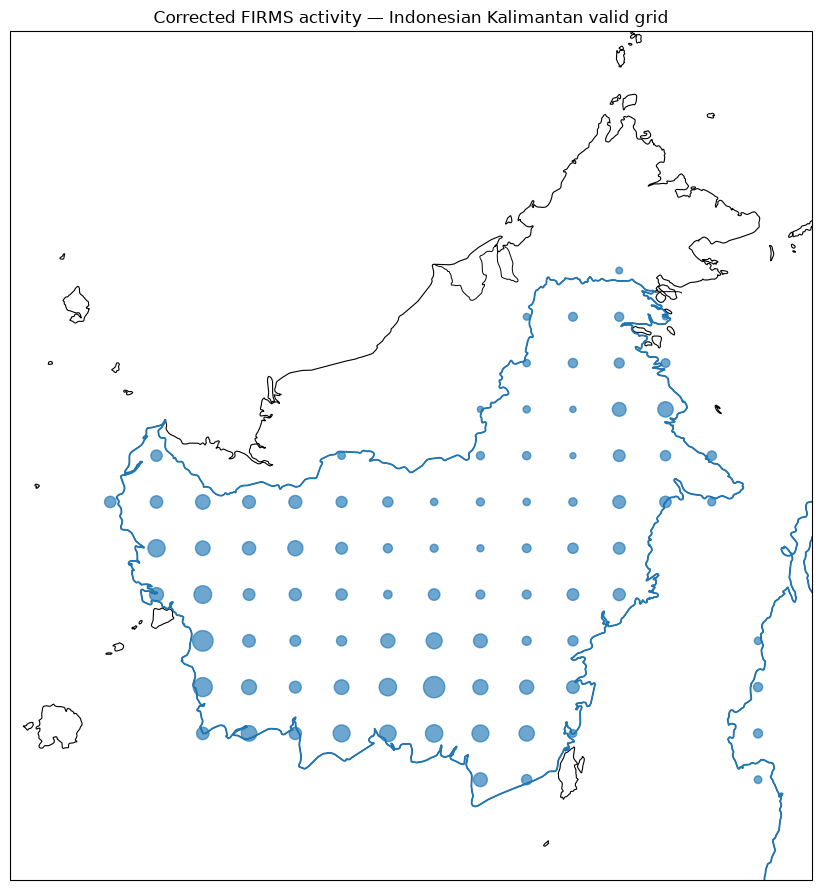

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_domain_correction\figures\04_corrected_fire_activity.png


In [31]:
# 29. Corrected activity by grid cell

corrected_cell_activity = (
    corrected_panel
    .groupby(
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
        ],
        as_index=False,
    )
    .agg(
        total_fire_count=("fire_count", "sum"),
        active_cell_days=("fire_active", "sum"),
    )
)

plot_data = corrected_cell_activity[
    corrected_cell_activity["total_fire_count"] > 0
].copy()

fig = plt.figure(figsize=(10, 9))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(
    [minx - 0.5, maxx + 0.5, miny - 0.5, maxy + 0.5],
    crs=ccrs.PlateCarree(),
)

ax.add_feature(
    cfeature.COASTLINE.with_scale("10m"),
    linewidth=0.8,
)

ax.add_feature(
    cfeature.BORDERS.with_scale("10m"),
    linewidth=0.7,
)

kalimantan_gdf.boundary.plot(
    ax=ax,
    linewidth=1.3,
    transform=ccrs.PlateCarree(),
)

if len(plot_data):
    max_count = plot_data["total_fire_count"].max()

    marker_size = (
        15
        + 220
        * np.sqrt(
            plot_data["total_fire_count"]
            / max_count
        )
    )

    ax.scatter(
        plot_data["grid_lon"],
        plot_data["grid_lat"],
        s=marker_size,
        alpha=0.65,
        transform=ccrs.PlateCarree(),
    )

ax.set_title(
    "Corrected FIRMS activity — Indonesian Kalimantan valid grid"
)

plt.tight_layout()

fig_path = FIGURES_DIR / "04_corrected_fire_activity.png"
plt.savefig(fig_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 30. Corrected Emerging-event map

This figure shows seven-day Emerging next-day positives after spatial-domain correction.

Corrected cells with >=1 seven-day Emerging event: 86


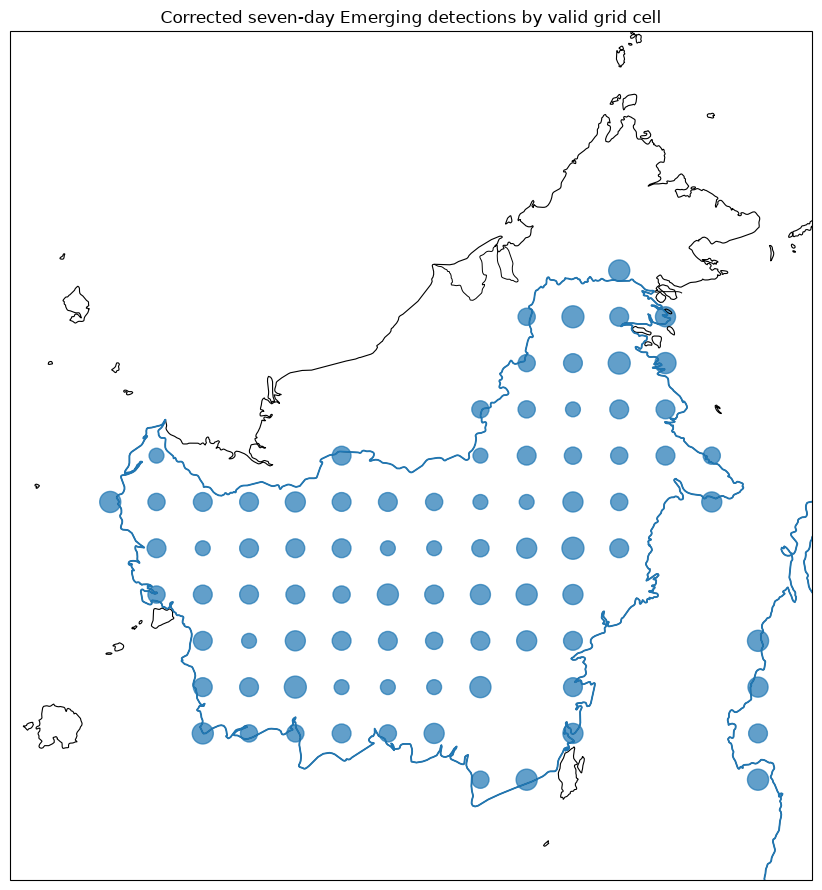

Saved: c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_domain_correction\figures\05_corrected_emerging_7d.png


In [32]:
# 30. Corrected Emerging map

corrected_emerging_by_cell = (
    corrected_model_panel
    .groupby(
        [
            "cell_id",
            "grid_lat",
            "grid_lon",
        ],
        as_index=False,
    )
    .agg(
        emerging_7d=(
            "event_type_7d",
            lambda s: (s == "Emerging").sum(),
        ),
        emerging_3d=(
            "event_type_3d",
            lambda s: (s == "Emerging").sum(),
        ),
    )
)

plot_data = corrected_emerging_by_cell[
    corrected_emerging_by_cell["emerging_7d"] > 0
].copy()

print(
    "Corrected cells with >=1 seven-day Emerging event:",
    len(plot_data),
)

fig = plt.figure(figsize=(10, 9))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(
    [minx - 0.5, maxx + 0.5, miny - 0.5, maxy + 0.5],
    crs=ccrs.PlateCarree(),
)

ax.add_feature(
    cfeature.COASTLINE.with_scale("10m"),
    linewidth=0.8,
)

ax.add_feature(
    cfeature.BORDERS.with_scale("10m"),
    linewidth=0.7,
)

kalimantan_gdf.boundary.plot(
    ax=ax,
    linewidth=1.3,
    transform=ccrs.PlateCarree(),
)

if len(plot_data):
    max_count = plot_data["emerging_7d"].max()

    marker_size = (
        20
        + 230
        * np.sqrt(
            plot_data["emerging_7d"]
            / max_count
        )
    )

    ax.scatter(
        plot_data["grid_lon"],
        plot_data["grid_lat"],
        s=marker_size,
        alpha=0.70,
        transform=ccrs.PlateCarree(),
    )

ax.set_title(
    "Corrected seven-day Emerging detections by valid grid cell"
)

plt.tight_layout()

fig_path = FIGURES_DIR / "05_corrected_emerging_7d.png"
plt.savefig(fig_path, dpi=180, bbox_inches="tight")
plt.show()

print("Saved:", fig_path)

## 31. Inspect high-activity corrected cells

This table can be used at the next supervision meeting instead of the approximate province table from Notebook 12.

It is safer because every listed node belongs to the corrected Indonesian Kalimantan domain.

In [33]:
# 31. Top corrected cells

top_corrected_cells = (
    corrected_cell_activity
    .merge(
        valid_grid[
            [
                "cell_id",
                "kalimantan_overlap_fraction",
                "center_inside_kalimantan",
            ]
        ],
        on="cell_id",
        how="left",
        validate="one_to_one",
    )
    .merge(
        corrected_emerging_by_cell,
        on=[
            "cell_id",
            "grid_lat",
            "grid_lon",
        ],
        how="left",
        validate="one_to_one",
    )
    .fillna({
        "emerging_7d": 0,
        "emerging_3d": 0,
    })
    .sort_values(
        "total_fire_count",
        ascending=False,
    )
)

display(
    top_corrected_cells.head(25)
)

,cell_id,grid_lat,grid_lon,total_fire_count,active_cell_days,kalimantan_overlap_fraction,center_inside_kalimantan,emerging_7d,emerging_3d
26,Kalimantan_-2.25_114.00,-2.25,114.00,13251,60,1.000000,True,1,3
11,Kalimantan_-1.50_110.25,-1.50,110.25,11267,78,0.831393,True,3,5
21,Kalimantan_-2.25_110.25,-2.25,110.25,8032,75,0.655494,True,3,7
1,Kalimantan_-0.75_110.25,-0.75,110.25,5845,71,0.997368,True,3,6
25,Kalimantan_-2.25_113.25,-2.25,113.25,5517,59,1.000000,True,1,4
36,Kalimantan_-3.00_114.00,-3.00,114.00,5459,59,0.976820,True,4,7
44,Kalimantan_0.00_109.50,0.00,109.50,5259,76,0.956682,True,3,8
34,Kalimantan_-3.00_112.50,-3.00,112.50,4903,72,0.958826,True,3,4
37,Kalimantan_-3.00_114.75,-3.00,114.75,4831,93,0.998869,True,0,5
35,Kalimantan_-3.00_113.25,-3.00,113.25,4387,48,0.700699,True,2,6


## 32. Save corrected node table

The saved node table is the intended starting point for the later graph construction.

It contains:

- node/cell ID
- grid center coordinate
- Kalimantan overlap fraction
- whether the center lies inside Kalimantan
- valid-node flag

In [34]:
# 32. Corrected graph-node table

corrected_nodes = valid_grid[
    [
        "cell_id",
        "grid_lat",
        "grid_lon",
        "cell_area_km2",
        "kalimantan_area_km2",
        "kalimantan_overlap_fraction",
        "center_inside_kalimantan",
        "keep_corrected",
    ]
].copy()

corrected_nodes = (
    corrected_nodes
    .sort_values(
        ["grid_lat", "grid_lon"]
    )
    .reset_index(drop=True)
)

corrected_nodes["node_index"] = np.arange(
    len(corrected_nodes)
)

corrected_nodes = corrected_nodes[
    [
        "node_index",
        "cell_id",
        "grid_lat",
        "grid_lon",
        "cell_area_km2",
        "kalimantan_area_km2",
        "kalimantan_overlap_fraction",
        "center_inside_kalimantan",
        "keep_corrected",
    ]
]

display(corrected_nodes.head(20))

,node_index,cell_id,grid_lat,grid_lon,cell_area_km2,kalimantan_area_km2,kalimantan_overlap_fraction,center_inside_kalimantan,keep_corrected
0,0,Kalimantan_-3.75_114.75,-3.75,114.75,6909.376219,4753.469871,0.687974,True,True
1,1,Kalimantan_-3.75_115.50,-3.75,115.50,6909.376219,3959.643914,0.573083,True,True
2,2,Kalimantan_-3.75_119.25,-3.75,119.25,6909.376219,1754.683443,0.253957,False,True
3,3,Kalimantan_-3.00_110.25,-3.00,110.25,6914.569660,1479.511762,0.213970,False,True
4,4,Kalimantan_-3.00_111.00,-3.00,111.00,6914.569660,3643.463593,0.526926,True,True
5,5,Kalimantan_-3.00_111.75,-3.00,111.75,6914.569660,4498.352382,0.650561,False,True
6,6,Kalimantan_-3.00_112.50,-3.00,112.50,6914.569660,6629.868915,0.958826,True,True
7,7,Kalimantan_-3.00_113.25,-3.00,113.25,6914.569660,4845.031885,0.700699,True,True
8,8,Kalimantan_-3.00_114.00,-3.00,114.00,6914.569660,6754.289812,0.976820,True,True
9,9,Kalimantan_-3.00_114.75,-3.00,114.75,6914.569660,6906.745954,0.998869,True,True


## 33. Save corrected outputs

Nothing is written over the old pipeline.

Outputs include:

- corrected complete fire panel
- corrected model-period panel + Emerging labels
- corrected graph-node table
- threshold sensitivity
- raw spatial-filter summary
- original-vs-corrected summary
- corrected top-cell summary

In [35]:
# 33. Save corrected outputs

corrected_panel_path = (
    OUTPUT_DIR
    / "fire_kalimantan_cell_day_corrected.csv"
)

corrected_model_path = (
    OUTPUT_DIR
    / "fire_kalimantan_model_panel_corrected.csv"
)

corrected_nodes_path = (
    OUTPUT_DIR
    / "kalimantan_graph_nodes_corrected.csv"
)

threshold_summary_path = (
    RESULTS_DIR
    / "node_overlap_threshold_sensitivity.csv"
)

comparison_path = (
    RESULTS_DIR
    / "original_vs_corrected_summary.csv"
)

split_summary_path = (
    RESULTS_DIR
    / "corrected_split_summary.csv"
)

event_summary_path = (
    RESULTS_DIR
    / "corrected_event_summary.csv"
)

top_cells_path = (
    RESULTS_DIR
    / "top_corrected_cells.csv"
)

removed_points_summary_path = (
    RESULTS_DIR
    / "raw_firms_spatial_filter_summary.csv"
)

mask_comparison_path = (
    RESULTS_DIR
    / "notebook12_vs_corrected_mask.csv"
)

corrected_panel.to_csv(
    corrected_panel_path,
    index=False,
)

corrected_model_panel.to_csv(
    corrected_model_path,
    index=False,
)

corrected_nodes.to_csv(
    corrected_nodes_path,
    index=False,
)

threshold_summary.to_csv(
    threshold_summary_path,
    index=False,
)

comparison_summary.to_csv(
    comparison_path,
    index=False,
)

corrected_split_summary.to_csv(
    split_summary_path
)

corrected_event_summary.to_csv(
    event_summary_path,
    index=False,
)

top_corrected_cells.to_csv(
    top_cells_path,
    index=False,
)

spatial_filter_summary = pd.DataFrame([{
    "raw_firms_points": len(fire_points),
    "retained_kalimantan_points": len(fire_kalimantan),
    "removed_outside_kalimantan_points": len(fire_removed),
    "retention_rate": len(fire_kalimantan) / len(fire_points),
    "default_overlap_threshold": DEFAULT_OVERLAP_THRESHOLD,
    "original_grid_cells": len(grid_gdf),
    "corrected_valid_cells": len(valid_grid),
    "corrected_excluded_cells": len(invalid_grid),
    "max_assignment_distance_km": fire_assigned[
        "assignment_distance_km"
    ].max(),
    "assignments_over_100km": len(long_assignments),
}])

spatial_filter_summary.to_csv(
    removed_points_summary_path,
    index=False,
)

if mask_comparison is not None:
    mask_comparison.to_csv(
        mask_comparison_path,
        index=False,
    )

print("Saved corrected outputs:")
for path in [
    corrected_panel_path,
    corrected_model_path,
    corrected_nodes_path,
    threshold_summary_path,
    comparison_path,
    split_summary_path,
    event_summary_path,
    top_cells_path,
    removed_points_summary_path,
]:
    print("-", path)

if mask_comparison is not None:
    print("-", mask_comparison_path)

Saved corrected outputs:
- c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\spatial_corrected\fire_kalimantan_cell_day_corrected.csv
- c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\spatial_corrected\fire_kalimantan_model_panel_corrected.csv
- c:\Users\Asus\Documents\skripsi-karhut\data\intermediate\spatial_corrected\kalimantan_graph_nodes_corrected.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_domain_correction\node_overlap_threshold_sensitivity.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_domain_correction\original_vs_corrected_summary.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_domain_correction\corrected_split_summary.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_domain_correction\corrected_event_summary.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_domain_correction\top_corrected_cells.csv
- c:\Users\Asus\Documents\skripsi-karhut\model_results\spatial_domai

## 34. Final automatic diagnostic

This is the output to send for review before moving to wind-direction analysis.

In [36]:
# 34. Key diagnostic summary

original_detection_total = int(
    original_panel["fire_count"].sum()
)

corrected_detection_total = int(
    corrected_panel["fire_count"].sum()
)

print("=== Notebook 12B spatial-domain correction ===")
print()
print("RAW POINT FILTER")
print("Raw FIRMS points              :", len(fire_points))
print("Retained on Indonesian Kalimantan:", len(fire_kalimantan))
print("Removed outside Kalimantan    :", len(fire_removed))
print(
    "Retained %",
    round(
        100 * len(fire_kalimantan) / len(fire_points),
        2,
    ),
)
print()
print("NODE DOMAIN")
print("Original rectangular cells    :", len(grid_gdf))
print("Corrected valid cells          :", len(valid_grid))
print("Corrected excluded cells       :", len(invalid_grid))
print(
    "Default overlap threshold     :",
    DEFAULT_OVERLAP_THRESHOLD,
)
print()
print("ASSIGNMENT QA")
print(
    "Median assignment distance km :",
    round(
        fire_assigned["assignment_distance_km"].median(),
        2,
    ),
)
print(
    "95th percentile distance km   :",
    round(
        fire_assigned["assignment_distance_km"].quantile(0.95),
        2,
    ),
)
print(
    "Max assignment distance km    :",
    round(
        fire_assigned["assignment_distance_km"].max(),
        2,
    ),
)
print(
    "Assignments >100 km           :",
    len(long_assignments),
)
print()
print("AGGREGATED DETECTIONS")
print("Original total detections      :", original_detection_total)
print("Corrected total detections     :", corrected_detection_total)
print(
    "Difference                    :",
    corrected_detection_total
    - original_detection_total,
)
print()
print("CORRECTED MODEL WINDOW")
print(
    "Rows                          :",
    len(corrected_model_panel),
)
print(
    "Positive next-day targets     :",
    int(
        corrected_model_panel[
            "target_fire_active_t1"
        ].sum()
    ),
)
print(
    "7-day Emerging                :",
    corrected_total_emerging_7d,
)
print(
    "7-day Persistent              :",
    corrected_total_persistent_7d,
)

=== Notebook 12B spatial-domain correction ===

RAW POINT FILTER
Raw FIRMS points              : 146314
Retained on Indonesian Kalimantan: 140171
Removed outside Kalimantan    : 6143
Retained % 95.8

NODE DOMAIN
Original rectangular cells    : 272
Corrected valid cells          : 94
Corrected excluded cells       : 178
Default overlap threshold     : 0.2

ASSIGNMENT QA
Median assignment distance km : 31.01
95th percentile distance km   : 50.95
Max assignment distance km    : 73.21
Assignments >100 km           : 0

AGGREGATED DETECTIONS
Original total detections      : 146314
Corrected total detections     : 140171
Difference                    : -6143

CORRECTED MODEL WINDOW
Rows                          : 11844
Positive next-day targets     : 4658
7-day Emerging                : 260
7-day Persistent              : 4398


# Decision rule before Notebook 13

Do **not** proceed automatically to wind analysis only because this notebook runs.

Review these outputs first:

1. `node_overlap_threshold_sensitivity`
2. number of raw FIRMS points removed outside Kalimantan
3. assignment-distance distribution
4. corrected number of valid nodes
5. corrected Emerging/Persistent counts
6. map `02_corrected_valid_grid_cells.png`
7. map `03_raw_firms_spatial_filter.png`
8. map `05_corrected_emerging_7d.png`

---

## When the corrected domain is acceptable

Then Notebook 13 should use:

- `kalimantan_graph_nodes_corrected.csv`
- `fire_kalimantan_model_panel_corrected.csv`

and **not** the old 272-cell rectangle.

However, the corrected fire panel does not yet contain the rebuilt weather variables.  
Before GAT training, weather must be joined again to the corrected node/date panel using the same no-leakage logic as Notebook 04.

The immediate next experiment can still be the **wind-direction spatial diagnostic**, because it can join the existing weather source to these corrected cell coordinates without retraining the benchmark yet.